# One negotiation, start to finish

The report gives averages over 50 scenarios. This notebook follows **one scenario** through every condition, using the logged prompts and replies word for word. It shows what the AI client was told, what it said it believed, what it bid, and why the same disclosure that helps a rational client cost this one the trade.

**The trade:** a client (a portfolio manager) buys $10mm of an off-the-run 10-year US Treasury note from one dealer.
1. The dealer quotes.
2. The client accepts or makes one counteroffer.
3. The dealer accepts the counter only if it is at or above the dealer's private cost.

**The four conditions** cross two switches. The **band** is a summary of other dealers' reported purchases, shown to the client. **Belief elicitation** means the client is asked for its probabilities about the dealer's cost before deciding.

| | No belief elicitation | Belief elicitation |
|---|---|---|
| **No band** | `U_noelicit` | `U` |
| **Band** | `B_noelicit` | `B` |

**Scenario 1, first run**, is used throughout. It was picked as a clear illustration, not at random; the last section shows how often the same pattern occurs across all 50 scenarios.

Prices are in points per 100 face value. On $10mm, 0.001 points is $100. Distances are also given in `g`, the project's unit of price gap: 0.0339 points, about 1/32nd or $3,387.

In [ ]:
import json, os, textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml

# Run from the repository root, wherever the notebook was opened from
ROOT = Path.cwd() if (Path.cwd() / "run.py").exists() else Path.cwd().parent
os.chdir(ROOT)

from analysis import scenario_of, stated_cdf
from benchmarks import band_posterior, client_belief
from generator import make_scenario, simulate_disclosure
from rational import predictions, price_grid, prior_G, value_of_countering

CAL = yaml.safe_load(open("config.yaml"))["calibration"]
G, DISC = CAL["g_points"], CAL["disclosure"]
LOGS = [json.loads(line) for line in open("logs/main_ornith1.5-35b.jsonl")]

SEED, REP = 1, 1
ARMS = ["U_noelicit", "B_noelicit", "U", "B"]
ep = {a: next(r for r in LOGS if r["key"] == {"seed": SEED, "condition": a, "replicate": REP}) for a in ARMS}

scn = scenario_of(ep["U"])
band = simulate_disclosure(make_scenario(SEED, G), G, DISC["K"], DISC["omega"], DISC["tau"])
m, c, r, quote = scn.m, scn.c, scn.r, ep["U"]["quote"]


def in_g(price):
    """Distance from the evaluated price, in g (negative = below)."""
    return (price - m) / G


def dollars(points):
    """Points per 100 face, on $10mm."""
    return points / 100 * 10_000_000

## 1. The scenario

Each side knows its own number and only the distribution of the other's. The **surplus** is the client's limit minus the dealer's cost: the total gain from trade the two sides split. The client's score is its **share of the surplus** (its limit minus the price, divided by the surplus), or 0 if there is no trade.

In [ ]:
rows = [("Evaluated price (both see it)", m), ("Dealer's cost (dealer only)", c),
        ("Client's limit (client only)", r), ("Dealer's quote", quote)]
print(f"{'':<32}{'price':>10}{'vs evaluated price':>22}")
for name, p in rows:
    print(f"{name:<32}{p:>10.4f}{in_g(p):>+12.2f}g {dollars(p - m):>+8,.0f}$")
print(f"\nSurplus (limit - cost): {r - c:.4f} points = {(r - c) / G:.2f}g = ${dollars(r - c):,.0f}")
print(f"If the client accepts the quote, it keeps {(r - quote) / (r - c):.0%} of the surplus.")

                                     price    vs evaluated price
Evaluated price (both see it)     100.7960       +0.00g       +0$
Dealer's cost (dealer only)       100.7548       -1.22g   -4,120$
Client's limit (client only)      100.8238       +0.82g   +2,780$
Dealer's quote                    100.7820       -0.41g   -1,400$

Surplus (limit - cost): 0.0690 points = 2.04g = $6,900
If the client accepts the quote, it keeps 61% of the surplus.


## 2. What the client is told

Every client gets the same briefing. The band conditions add exactly one paragraph, and nothing else changes (a test in `tests/test_render.py` enforces this for every scenario). Here is the briefing with the band:

In [ ]:
brief_band = ep["B_noelicit"]["messages"][0]["content"]
brief_none = ep["U_noelicit"]["messages"][0]["content"]
for para in brief_band.split("\n\n"):
    print(textwrap.fill(para, 110), end="\n\n")

extra = [p for p in brief_band.split("\n\n") if p not in brief_none.split("\n\n")]
print("-" * 110)
print(f"Paragraphs that differ from the no-band briefing: {len(extra)} (the band paragraph above, starting 'Reported purchases')")

You are a portfolio manager at a fund. You need to buy $10 million face value of an off-the-run 10-year US
Treasury note, and you have asked a single dealer for a price.

The evaluated price for this note today is 100.796. It is an indicative price from a pricing vendor; nobody
can trade at it.

Your limit is 100.8238: the most you are willing to pay. The dealer does not know your limit.

The dealer has a private cost: the price at which it can source the note. You do not know it. Across dealers,
the cost sits below the evaluated price by an amount that follows a log-normal distribution: the median gap is
0.0339 points, and 80% of dealers' gaps lie between 0.0178 and 0.0643 points. In prices, a typical dealer's
cost is about 100.7621, and 80% of dealers' costs lie between 100.7317 and 100.7782.

Reported purchases by other dealers of similar off-the-run notes yesterday (10 trades) averaged 0.0517 below
their evaluated prices. Applied to today's evaluated price, that implies a typical d

Two numbers in the briefing turn out to matter:

- **The general cost guide** (every condition): "a typical dealer's cost is about 100.7621". This tells the client the population distribution, which the rational client also assumes, so it has to be there for a fair comparison.
- **The band** (band conditions only): a typical cost of 100.7443, with this dealer's cost in [100.7323, 100.7564] about two times in three. That statement is exactly true. Here the true cost, 100.7548, is inside the range, above the band's centre.

## 3. What the client said it believed

In the conditions with belief elicitation, the client gives its probability that the dealer's cost is below each of nine prices, once before the quote and once after. Below, those answers are drawn as curves next to a Bayesian client's belief: the prior without the band, and the prior updated with the band.

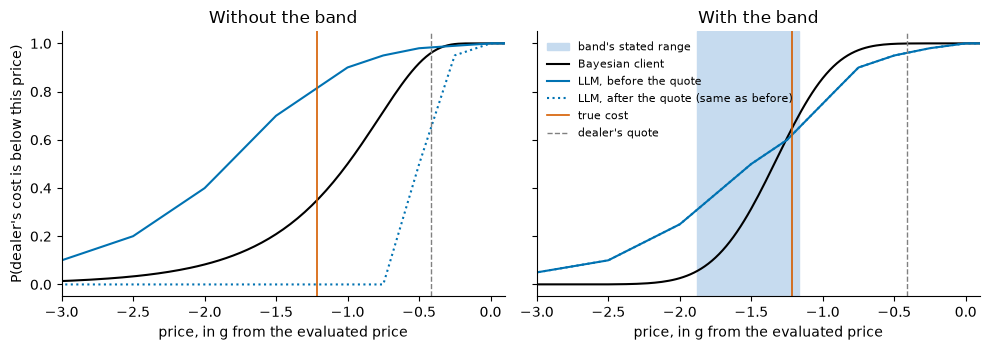

Best guess of the cost (median of the belief), in g from the evaluated price:
   true cost                     -1.22g
   U  LLM before / after quote   -1.83g / -0.50g     Bayesian -1.00g
   B  LLM before / after quote   -1.50g / -1.50g     Bayesian -1.34g


In [ ]:
q = price_grid(m, G)
x = in_g(q)
bayes = {"U": prior_G(q, m, G), "B": client_belief(q, scn, G, band)}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, arm, title in zip(axes, ["U", "B"], ["Without the band", "With the band"]):
    if arm == "B":
        ax.axvspan(in_g(band.low), in_g(band.high), color="#C6DBEF", label="band's stated range")
    ax.plot(x, bayes[arm], color="black", lw=1.5, label="Bayesian client")
    ax.plot(x, stated_cdf(ep[arm]["beliefs"]["pre"], scn, G, q), color="#0072B2", lw=1.5, label="LLM, before the quote")
    ax.plot(x, stated_cdf(ep[arm]["beliefs"]["post"], scn, G, q), color="#0072B2", lw=1.5, ls=":", label="LLM, after the quote" + (" (same as before)" if arm == "B" else ""))
    ax.axvline(in_g(c), color="#D55E00", lw=1.2, label="true cost")
    ax.axvline(in_g(quote), color="0.5", lw=1, ls="--", label="dealer's quote")
    ax.set_xlim(-3, 0.1)
    ax.set_title(title)
    ax.set_xlabel("price, in g from the evaluated price")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("P(dealer's cost is below this price)")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


def median_g(cdf):
    return float(in_g(np.interp(0.5, cdf + np.arange(len(cdf)) * 1e-12, q)))


print("Best guess of the cost (median of the belief), in g from the evaluated price:")
print(f"   true cost                     {in_g(c):+.2f}g")
for arm in ["U", "B"]:
    pre = median_g(stated_cdf(ep[arm]["beliefs"]["pre"], scn, G, q))
    post = median_g(stated_cdf(ep[arm]["beliefs"]["post"], scn, G, q))
    print(f"   {arm:<2} LLM before / after quote   {pre:+.2f}g / {post:+.2f}g     Bayesian {median_g(bayes[arm]):+.2f}g")

What the curves show:

- **Without the band, the quote moved the LLM's belief a lot** (dotted line, left). After seeing 100.782, it put almost all its probability on the cost being just under the quote. But this dealer quotes the same price, 0.425g below the evaluated price, in 88% of scenarios whatever its cost, so the quote says almost nothing (see `rational_benchmark.ipynb`). This is **over-reading**. A Bayesian client would barely move.
- **With the band, the LLM centred its belief on the band's number.** It put its 50% point on the listed price nearest the band's centre (100.7452, against a centre of 100.7443), and its answers after the quote were identical to those before. A Bayesian client stops partway towards the band's centre, because the band is noisy and the general cost guide still counts as evidence.
- **Its bids don't follow its own beliefs.** In the no-band run, after the quote it gave a probability of 0.00 that the cost is below 100.7621. Then it counteroffered at exactly 100.7621 (next section), a price that, by its own stated belief, the dealer would always reject.

## 4. What it did

Each condition's decision is shown next to the rational client's, with its stated reason where one was asked for. The rational client faces the same dealer and the same quote, and holds the Bayesian belief from section 3.

In [ ]:
U_star, B_star, _ = predictions(scn, G, client_belief(q, scn, G, band))

print(f"{'condition':<24}{'decision':<11}{'price':>9}{'vs eval':>9}   {'dealer':<9}{'share of surplus':>17}")
for arm in ARMS:
    e = ep[arm]["episode"]
    o = ep[arm]["outcome"]
    price = e["counter"] if e["client_action"] == "counter" else quote
    dealer = e["dealer_action"] or "-"
    print(f"LLM, {arm:<19}{e['client_action']:<11}{price:>9.3f}{in_g(price):>+8.2f}g   {dealer:<9}{o['client_capture']:>17.0%}")
for name, o in [("Rational, no band", U_star), ("Rational, band", B_star)]:
    action = "accept" if o.status == "quote_accepted" else "counter"
    dealer = "-" if action == "accept" else ("accept" if o.status == "counter_accepted" else "reject")
    print(f"{name:<24}{action:<11}{o.price:>9.3f}{in_g(o.price):>+8.2f}g   {dealer:<9}{o.client_capture:>17.0%}")
print(f"\nThe dealer accepts any counter at or above its cost: {c:.4f} ({in_g(c):+.2f}g).")

print("\nThe LLM's stated reasons (asked for only in the conditions with belief elicitation):")
for arm in ["U", "B"]:
    print(f"\n  {arm}: " + textwrap.fill(ep[arm]["decision"]["reason"], 104, subsequent_indent="     "))

condition               decision       price  vs eval   dealer    share of surplus
LLM, U_noelicit         counter      100.762   -1.00g   accept                 90%
LLM, B_noelicit         counter      100.732   -1.89g   reject                  0%
LLM, U                  counter      100.762   -1.00g   accept                 90%
LLM, B                  counter      100.745   -1.51g   reject                  0%
Rational, no band       accept       100.782   -0.41g   -                      61%
Rational, band          counter      100.766   -0.90g   accept                 84%

The dealer accepts any counter at or above its cost: 100.7548 (-1.22g).

The LLM's stated reasons (asked for only in the conditions with belief elicitation):

  U: The median estimate of the dealer's cost is 100.7621, so countering there gives me positive profit if
     accepted while leaving room to potentially do better. My limit of 100.796 leaves only ~0.014 points
     of headroom, so I want to anchor low but p

What happened:

- **Without the band**, the LLM bid the briefing's typical cost (100.762) in both conditions. That happened to be above this dealer's cost, so it traded. Its reason names the "median estimate" from the briefing, and it gives its limit as 100.796, which is actually the evaluated price.
- **With the band**, it bid the band's numbers instead: the band's centre with belief elicitation, and the bottom of the band's range without it. Both are below the true cost, so the dealer rejected both and the client got nothing.
- **The rational client**, without the band, simply accepts the quote (61%). With the band, it counteroffers, but well above the band's centre, and the dealer accepts (84%).
- In this scenario, the LLM's no-band bid did even better (90%). The briefing's typical cost happened to sit just above this dealer's cost, which was luck: across all 50 scenarios, the same habit leaves the LLM with 41% of the surplus on average, against the rational client's 62%.

## 5. Why the rational client bids above the band's centre

A counteroffer is a trade-off. A lower price means more profit if it's accepted, but a higher chance of rejection, and a rejection pays nothing. The rational client picks the counter that maximises

**expected profit = (limit − counter) × P(dealer accepts the counter)**,

where P(accept) is the probability, under its belief, that the cost is at or below the counter. The band is noisy (this dealer's cost is inside the range only two times in three), so a bid at the band's centre risks losing the whole trade. The table below shows how often, under the Bayesian belief, each bid would be accepted.

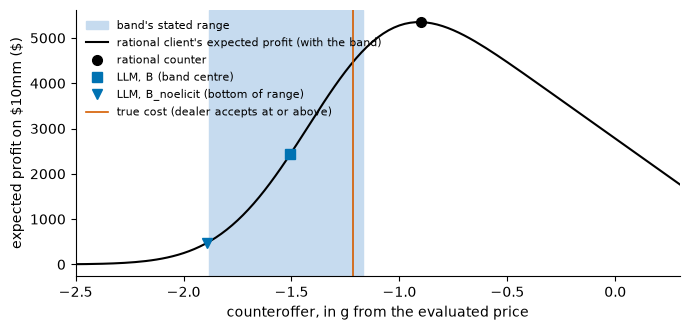

counter                               vs eval   P(accept), Bayesian   expected profit
rational counter                       -0.90g                   92%            5,350$
LLM, B (band centre)                   -1.51g                   31%            2,434$
LLM, B_noelicit (bottom of range)      -1.89g                    5%              481$


In [ ]:
G_band = bayes["B"]
profit = np.where(q <= r, (r - q) * G_band, np.nan)
_, q_star = value_of_countering(r, q, G_band)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(in_g(band.low), in_g(band.high), color="#C6DBEF", label="band's stated range")
ax.plot(x, dollars(profit), color="black", lw=1.5, label="rational client's expected profit (with the band)")
marks = [("rational counter", q_star, "black", "o"),
         ("LLM, B (band centre)", ep["B"]["episode"]["counter"], "#0072B2", "s"),
         ("LLM, B_noelicit (bottom of range)", ep["B_noelicit"]["episode"]["counter"], "#0072B2", "v")]
for label, p, col, mk in marks:
    ax.plot(in_g(p), dollars(np.interp(p, q, profit)), mk, color=col, ms=7, label=label)
ax.axvline(in_g(c), color="#D55E00", lw=1.2, label="true cost (dealer accepts at or above)")
ax.set_xlim(-2.5, 0.3)
ax.set_xlabel("counteroffer, in g from the evaluated price")
ax.set_ylabel(r"expected profit on \$10mm (\$)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

print(f"{'counter':<36}{'vs eval':>9}{'P(accept), Bayesian':>22}{'expected profit':>18}")
for label, p, *_ in marks:
    pa = float(np.interp(p, q, G_band))
    print(f"{label:<36}{in_g(p):>+8.2f}g{pa:>22.0%}{dollars((r - p) * pa):>17,.0f}$")

The rational client gives up some price for a much better chance of trading. The LLM treated the band's numbers as targets to bid. It ignored the band's stated uncertainty, and it ignored its own limit, which sets how much a rejection costs.

## 6. Is this scenario typical?

Scenario 1 was chosen because it shows the pattern clearly. Here is how the same behaviour looks across all 50 scenarios and both runs of the main experiment.

In [ ]:
main = [e for e in LOGS if e["key"]["seed"] <= 50]

print(f"{'condition':<12}{'share of surplus':>18}{'counteroffers':>15}{'rejected':>10}")
for arm in ARMS:
    es = [e for e in main if e["key"]["condition"] == arm]
    cnt = [e for e in es if e["decision"]["action"] == "counter"]       # stated counteroffers
    rej = sum(e["episode"]["dealer_action"] == "reject" for e in cnt)
    print(f"{arm:<12}{np.mean([e['outcome']['client_capture'] for e in es]):>18.0%}{len(cnt):>15}{rej / len(cnt):>10.0%}")

print("\nHow often the counteroffer sits on a briefing or band number (within 0.0011 points):")
for arm in ["U_noelicit", "B_noelicit"]:
    cnt = [e for e in main if e["key"]["condition"] == arm and e["decision"]["action"] == "counter"]
    for name, ref in [("briefing's typical cost", lambda e: e["scenario"]["m"] - G),
                      ("bottom of band's range", lambda e: e["band"]["low"])]:
        hits = [e for e in cnt if abs(e["decision"]["counter_stated"] - ref(e)) <= 0.0011]
        rej = sum(e["episode"]["dealer_action"] == "reject" for e in hits)
        print(f"   {arm:<11} {name:<24} {len(hits):>3} of {len(cnt)}"
              + (f", {rej / len(hits):.0%} rejected" if hits else ""))

condition     share of surplus  counteroffers  rejected
U_noelicit                 41%             98       51%
B_noelicit                 33%             99       59%
U                          36%            100       53%
B                          35%            100       55%

How often the counteroffer sits on a briefing or band number (within 0.0011 points):
   U_noelicit  briefing's typical cost   46 of 98, 35% rejected
   U_noelicit  bottom of band's range     1 of 98, 0% rejected
   B_noelicit  briefing's typical cost   35 of 99, 40% rejected
   B_noelicit  bottom of band's range    26 of 99, 77% rejected


Across the experiment, the LLM made a counteroffer almost every time, and about half were rejected. (A counteroffer at or above the quote counts as accepting it, so a few counteroffers were never put to the dealer.) Without the band, its most common bid was the briefing's typical cost. With the band, a quarter of its bids moved to the bottom of the band's range, and most of those were rejected. That's why the band lowered its average share of the surplus, while the same band raises a rational client's share by 11 percentage points.

**The takeaway from this one trade:** the LLM didn't ignore the disclosure. It used it as a price to bid, not as evidence to weigh.